# Project 15: Learning Rate Scheduling & Optimization Dynamics

This project analyzes dynamic learning rate schedulers and optimizer behaviors:
`StepLR`, `CosineAnnealingLR`, `ExponentialLR`, and `ReduceLROnPlateau` with `Adam`, `SGD`, and `RMSprop`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from neurogebra.optim import (
    StepLR,
    CosineAnnealingLR,
    ExponentialLR,
    ReduceLROnPlateau,
    Adam,
    SGD,
    RMSprop,
)

print('[INFO] Optimization & LR scheduling module loaded.')


[INFO] Optimization & LR scheduling module loaded.


<string>:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


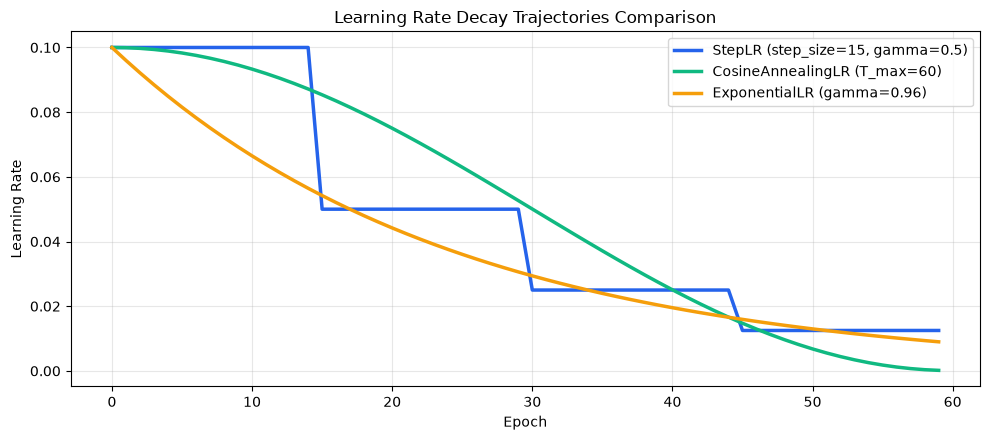

In [2]:
# Simulate and compare learning rate schedules over 60 epochs
epochs = 60
class DummyModel:
    def __init__(self, lr=0.1):
        self.learning_rate = lr

m1, m2, m3 = DummyModel(0.1), DummyModel(0.1), DummyModel(0.1)
sched_step = StepLR(m1, step_size=15, gamma=0.5)
sched_cosine = CosineAnnealingLR(m2, T_max=epochs, eta_min=1e-4)
sched_exp = ExponentialLR(m3, gamma=0.96)

lrs_step, lrs_cosine, lrs_exp = [], [], []
for ep in range(epochs):
    lrs_step.append(sched_step.step(ep))
    lrs_cosine.append(sched_cosine.step(ep))
    lrs_exp.append(sched_exp.step(ep))

# Visualize LR trajectories
plt.figure(figsize=(10, 4.5))
plt.plot(lrs_step, label='StepLR (step_size=15, gamma=0.5)', lw=2.5, color='#2563eb')
plt.plot(lrs_cosine, label='CosineAnnealingLR (T_max=60)', lw=2.5, color='#10b981')
plt.plot(lrs_exp, label='ExponentialLR (gamma=0.96)', lw=2.5, color='#f59e0b')
plt.title('Learning Rate Decay Trajectories Comparison')
plt.xlabel('Epoch')
plt.ylabel('Learning Rate')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


<string>:36: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


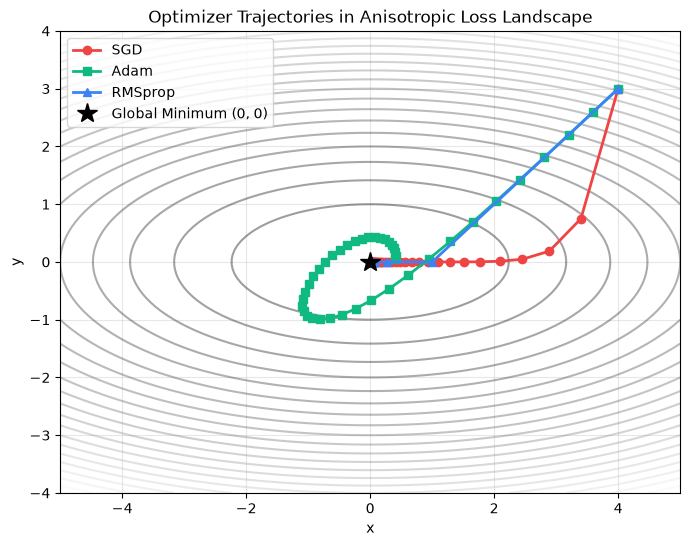

In [3]:
# Optimizer trajectory comparison on quadratic bowl
# f(x, y) = 0.5 * x^2 + 2.5 * y^2
class Param:
    def __init__(self, val):
        self.data = np.array(val, dtype=np.float64)
        self.grad = np.zeros_like(self.data)

def run_opt(opt_cls, lr, steps=40):
    p = Param([4.0, 3.0])
    opt = opt_cls(lr=lr)
    path = [p.data.copy()]
    for _ in range(steps):
        p.grad = np.array([p.data[0], 5.0 * p.data[1]])
        opt.step([p])
        path.append(p.data.copy())
    return np.array(path)

path_sgd = run_opt(SGD, lr=0.15)
path_adam = run_opt(Adam, lr=0.4)
path_rms = run_opt(RMSprop, lr=0.3)

plt.figure(figsize=(8, 6))
x = np.linspace(-5, 5, 100)
y = np.linspace(-4, 4, 100)
X, Y = np.meshgrid(x, y)
plt.contour(X, Y, 0.5 * X**2 + 2.5 * Y**2, levels=20, cmap='gray', alpha=0.4)
plt.plot(path_sgd[:, 0], path_sgd[:, 1], 'o-', label='SGD', color='#ef4444', lw=2)
plt.plot(path_adam[:, 0], path_adam[:, 1], 's-', label='Adam', color='#10b981', lw=2)
plt.plot(path_rms[:, 0], path_rms[:, 1], '^-', label='RMSprop', color='#3b82f6', lw=2)
plt.plot(0, 0, 'k*', markersize=15, label='Global Minimum (0, 0)')
plt.title('Optimizer Trajectories in Anisotropic Loss Landscape')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
